# Proyecto final — Modelos y Simulación II

**Universidad de Antioquia · Facultad de Ingeniería**

- **Equipo:** Samuel Puerta Patiño, Simón Berrio Gaviria, Juan Estiven Carmona Muñoz
- **Grupo:** 5 · **Semestre:** 2026-2 · **Dataset:** *Financial Transactions & Fraud Detection* (Kaggle)

## Discusión y modelo final (ítem 12 de la guía)

Este notebook cierra el proyecto. Las secciones 4 y 5 mostraron que los mejores modelos son equivalentes a usar `risk_score` directamente como puntaje y que alcanzan el techo de desempeño que permite la estructura de los datos. Aquí se responden las preguntas que quedan para la discusión:

| Apartado | Pregunta |
|---|---|
| 1 | ¿Por qué existe un techo de desempeño? |
| 2 | ¿Qué modelo se recomienda y cuánto rinde frente a `risk_score` usado solo? |
| 3 | ¿Cuántas alertas conviene revisar? (punto de operación) |
| 4 | ¿Cuánto dinero ahorra el modelo? (métrica de ahorro de Correa Bahnsen et al.) |
| 5 | ¿El modelo aprende algo real o es azar? (prueba de permutación) |
| 6 | ¿Mejoraría con más datos? (curva de aprendizaje) |
| 7 | ¿Cómo se compara con el estado del arte? |
| 8 | Discusión y conclusiones |

**Relación con el notebook 06.** Los apartados de este notebook usan las particiones aleatorias de los notebooks 03 y 04. En la asesoría, el profesor pidió evaluar con particiones temporales y no descartar variables; el notebook 06 lo hace y comprueba si las conclusiones se mantienen. La conclusión 8 integra sus resultados.

**Diseño común.** Se usan las **mismas 10 particiones externas** de los notebooks 03 y 04 (validación cruzada estratificada de 5 particiones repetida 2 veces, semilla `RANDOM_STATE + 1`). Los hiperparámetros son los que el notebook 03 eligió para el conjunto D: gradient boosting con tasa de aprendizaje 0,03, profundidad 2 y 200 iteraciones; Random Forest balanceado con 500 árboles, `min_samples_leaf` = 1, `max_features` = √p y todos los fraudes de entrenamiento en cada árbol. Como en el notebook 04, evaluar con hiperparámetros elegidos sobre el 80 % de entrenamiento introduce un optimismo leve; la estimación sin ese sesgo es la validación cruzada anidada del notebook 03. El techo (PR-AUC 0,122) se toma del notebook 04.

> **Ejecución.** Requiere `data/caracteristicas.csv` (lo genera el notebook 01). Ejecutar desde la carpeta `notebooks/`. Las pruebas de permutación y la curva de aprendizaje usan `N_JOBS` procesos (celda de configuración); la ejecución completa toma del orden de 10 minutos con 6 procesos.

## Configuración

In [1]:
from pathlib import Path
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, learning_curve, permutation_test_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.proportion import proportion_confint
from threadpoolctl import threadpool_limits

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42
N_JOBS = 6
N_PART, N_REP = 5, 2
N_PERMUTACIONES = 200
UMBRAL = 70
TECHO = 0.122
np.random.seed(RANDOM_STATE)
threadpool_limits(limits=N_JOBS)

DATA_PATH = Path("../data/caracteristicas.csv")
FIG_DIR = Path("../report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
COLORES = {"Gradient boosting": "#eb6834", "Random Forest balanceado": "#2a78d6",
           "Regla de umbral aprendido": "#1baf7a", "risk_score sin modelo": "#8a5cd0"}
COLOR_REF = "#52514e"


def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

In [2]:
df = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
y = df["is_fraud"].to_numpy()
riesgo = df["risk_score"].to_numpy()
monto = np.round(np.expm1(df["amount_log"].to_numpy()), 2)

ORIGINALES_NUM = ["amount_log", "hour_sin", "hour_cos"]
ORIGINALES_BIN = ["is_weekend"]
CATEGORICAS = ["account_type", "category", "payment_method", "device_type"]
CARACT_CONT = [
    "transacciones_previas", "horas_desde_anterior_log", "desvio_log_monto",
    "transacciones_24h", "transacciones_7d", "monto_7d_log", "anomalia_historial",
]
CARACT_BIN = [
    "primera_transaccion", "cambio_dispositivo", "cambio_metodo_pago",
    "cambio_categoria", "dispositivo_nuevo", "cuenta_pago_incoherente",
]
CONJUNTOS = {
    "B. Caracterizadas": dict(cont=ORIGINALES_NUM + CARACT_CONT, bin=ORIGINALES_BIN + CARACT_BIN),
    "D. Caracterizadas + risk": dict(cont=ORIGINALES_NUM + CARACT_CONT + ["risk_score"], bin=ORIGINALES_BIN + CARACT_BIN),
}


def construir_preprocesador(conjunto):
    v = CONJUNTOS[conjunto]
    return ColumnTransformer([
        ("cont", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), v["cont"]),
        ("bin", make_pipeline(SimpleImputer(strategy="constant", fill_value=0), StandardScaler()), v["bin"]),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])


def columnas(conjunto):
    v = CONJUNTOS[conjunto]
    return v["cont"] + v["bin"] + CATEGORICAS


def alertas_top(y_true, s, fraccion):
    k = int(np.ceil(fraccion * len(y_true)))
    return np.asarray(y_true)[np.argsort(-np.asarray(s), kind="stable")[:k]]


def precision_top(y_true, s, fraccion):
    return alertas_top(y_true, s, fraccion).mean()


def recall_top(y_true, s, fraccion):
    return alertas_top(y_true, s, fraccion).sum() / np.sum(y_true)


def metricas(y_true, s):
    return {"PR-AUC": average_precision_score(y_true, s), "ROC-AUC": roc_auc_score(y_true, s),
            "Precisión@1 %": precision_top(y_true, s, 0.01), "Recall@1 %": recall_top(y_true, s, 0.01),
            "Precisión@2 %": precision_top(y_true, s, 0.02), "Recall@2 %": recall_top(y_true, s, 0.02)}


R_NB = 1 / (N_PART - 1)


def ic_nb(v, r=R_NB, conf=0.95):
    v = np.asarray(v, dtype=float)
    k = len(v)
    h = stats.t.ppf((1 + conf) / 2, k - 1) * np.sqrt(v.var(ddof=1) * (1 / k + r))
    return v.mean(), v.mean() - h, v.mean() + h


def fmt_nb(v, r=R_NB):
    m, lo, hi = ic_nb(v, r)
    return f"{m:.3f} [{lo:.3f}, {hi:.3f}]"


def prueba_pareada_nb(a, b, r=R_NB):
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    k = len(d)
    var = d.var(ddof=1) * (1 / k + r)
    if var <= 0:
        return d.mean(), np.nan
    return d.mean(), 2 * stats.t.sf(abs(d.mean() / np.sqrt(var)), k - 1)


CV = RepeatedStratifiedKFold(n_splits=N_PART, n_repeats=N_REP, random_state=RANDOM_STATE + 1)
PARTICIONES = list(CV.split(df, y))
N_PRUEBA = len(PARTICIONES[0][1])
print(f"Transacciones: {len(df):,} | fraudes: {y.sum()} ({100 * y.mean():.2f} %) | particiones externas: {len(PARTICIONES)}")

Transacciones: 10,000 | fraudes: 126 (1.26 %) | particiones externas: 10


## 1. ¿Por qué existe un techo de desempeño?

Las secciones 2, 4 y 5 encontraron que la única variable con señal es `risk_score` y que el desempeño se estanca en una PR-AUC cercana a 0,12. Para la discusión interesa entender **por qué**. Se separan las transacciones en dos grupos según el umbral de `risk_score` = 70 y se revisa, **dentro de cada grupo**, si alguna variable distingue los fraudes de las transacciones normales:

- Tasa de fraude por intervalo de `risk_score`, con intervalo de Wilson al 95 %.
- Dentro de cada grupo, para las 22 variables: AUC univariada y prueba de Mann-Whitney para las continuas y binarias; V de Cramér con prueba de permutación (1.000 permutaciones) para las categóricas. Se corrige por multiplicidad con Benjamini–Hochberg en cada grupo.

El umbral 70 se identificó en el análisis exploratorio con todos los datos (sección 2), así que este apartado es **descriptivo**: explica la estructura observada, no estima desempeño.

,transacciones,fraudes,tasa de fraude (%),fracción de los fraudes (%)
risk_score ≥ 70,96,30,31.250,23.810
risk_score < 70,9904,96,0.969,76.190


Grupo bajo: tasa de fraude constante entre los 10 deciles de risk_score (χ²): p = 0.985
Grupo bajo: risk_score de los fraudes frente al de las normales (Kolmogorov–Smirnov): p = 0.835
Grupo alto: AUC de risk_score dentro del grupo = 0.517


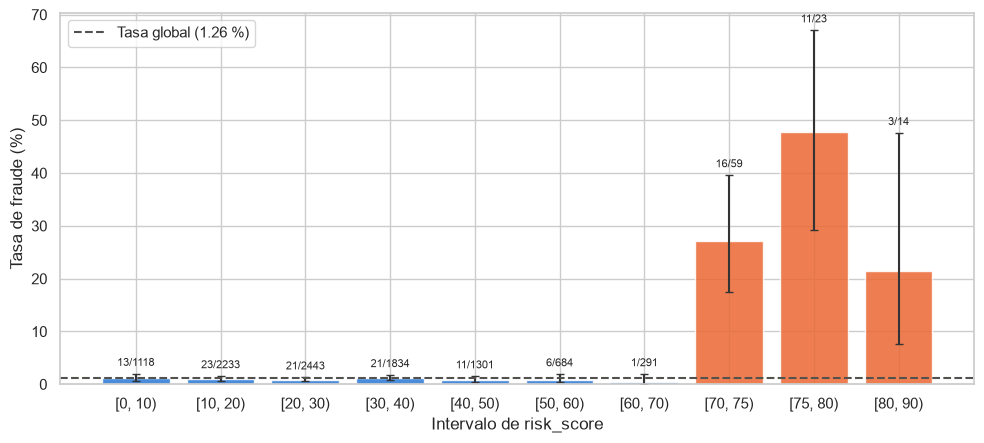

In [3]:
alto = riesgo >= UMBRAL
bajo = ~alto
grupos = pd.DataFrame({"transacciones": [alto.sum(), bajo.sum()], "fraudes": [y[alto].sum(), y[bajo].sum()]},
                      index=[f"risk_score ≥ {UMBRAL}", f"risk_score < {UMBRAL}"])
grupos["tasa de fraude (%)"] = 100 * grupos["fraudes"] / grupos["transacciones"]
grupos["fracción de los fraudes (%)"] = 100 * grupos["fraudes"] / y.sum()
display(grupos)

p_deciles = stats.chi2_contingency(pd.crosstab(pd.qcut(riesgo[bajo], 10), y[bajo]))[1]
p_ks = stats.ks_2samp(riesgo[bajo & (y == 1)], riesgo[bajo & (y == 0)]).pvalue
print(f"Grupo bajo: tasa de fraude constante entre los 10 deciles de risk_score (χ²): p = {p_deciles:.3f}")
print(f"Grupo bajo: risk_score de los fraudes frente al de las normales (Kolmogorov–Smirnov): p = {p_ks:.3f}")
print(f"Grupo alto: AUC de risk_score dentro del grupo = {roc_auc_score(y[alto], riesgo[alto]):.3f}")

CORTES = [0, 10, 20, 30, 40, 50, 60, 70, 75, 80, 90]
intervalo = pd.cut(df["risk_score"], CORTES, right=False)
tasas = df.groupby(intervalo, observed=True)["is_fraud"].agg(["sum", "count"])
tasa = (tasas["sum"] / tasas["count"]).to_numpy()
inf, sup = proportion_confint(tasas["sum"], tasas["count"], method="wilson")
inf, sup = np.asarray(inf), np.asarray(sup)

fig, ax = plt.subplots(figsize=(10, 4.6))
pos = np.arange(len(tasas))
color = ["#eb6834" if c.left >= UMBRAL else "#2a78d6" for c in tasas.index]
ax.bar(pos, 100 * tasa, color=color, alpha=0.85)
ax.errorbar(pos, 100 * tasa, yerr=[100 * (tasa - inf), 100 * (sup - tasa)], fmt="none", ecolor="#333333", capsize=3)
for p_, s_, f_, n_ in zip(pos, sup, tasas["sum"], tasas["count"]):
    ax.text(p_, 100 * s_ + 1.5, f"{f_}/{n_}", ha="center", fontsize=8)
ax.axhline(100 * y.mean(), ls="--", color=COLOR_REF, label=f"Tasa global ({100 * y.mean():.2f} %)")
ax.set_xticks(pos, [f"[{int(c.left)}, {int(c.right)})" for c in tasas.index])
ax.set_xlabel("Intervalo de risk_score")
ax.set_ylabel("Tasa de fraude (%)")
ax.legend()
savefig("fig_estructura_etiqueta")
plt.show()

*Figura (estructura de la etiqueta). Tasa de fraude por intervalo de `risk_score`, con intervalo de Wilson al 95 % y el número de fraudes sobre el de transacciones de cada intervalo. En naranja, los intervalos con `risk_score` ≥ 70. La línea discontinua es la tasa global de fraude.*

In [4]:
rng = np.random.default_rng(RANDOM_STATE)


def v_cramer(x, etiqueta):
    t = pd.crosstab(x, etiqueta).to_numpy()
    return np.sqrt(stats.chi2_contingency(t, correction=False)[0] / t.sum())


def p_permutacion(x, etiqueta, n=1000):
    obs = v_cramer(x, etiqueta)
    nulos = np.array([v_cramer(x, rng.permutation(etiqueta)) for _ in range(n)])
    return obs, (1 + (nulos >= obs).sum()) / (n + 1)


filas = []
for nombre_grupo, mascara in [(f"risk_score ≥ {UMBRAL}", alto), (f"risk_score < {UMBRAL}", bajo)]:
    sub, ys = df[mascara], y[mascara]
    for v in ORIGINALES_NUM + CARACT_CONT + ORIGINALES_BIN + CARACT_BIN + ["risk_score"]:
        x = sub[v].astype(float)
        x = x.fillna(x.median()).to_numpy()
        filas.append({"grupo": nombre_grupo, "variable": v, "estadístico": "AUC", "valor": roc_auc_score(ys, x),
                      "p": stats.mannwhitneyu(x[ys == 1], x[ys == 0]).pvalue})
    for v in CATEGORICAS:
        obs, p = p_permutacion(sub[v].to_numpy(), ys)
        filas.append({"grupo": nombre_grupo, "variable": v, "estadístico": "V de Cramér", "valor": obs, "p": p})
dentro = pd.DataFrame(filas)
dentro["q"] = dentro.groupby("grupo")["p"].transform(lambda p: stats.false_discovery_control(p))

display(dentro.pivot(index="variable", columns="grupo", values=["valor", "q"]).sort_values(("q", f"risk_score < {UMBRAL}")))
for grupo, g in dentro.groupby("grupo"):
    print(f"{grupo}: variables con q < 0,05 = {(g['q'] < 0.05).sum()} de {len(g)} · q mínimo = {g['q'].min():.3f}")

valor                               q                
grupo                    risk_score < 70 risk_score ≥ 70 risk_score < 70 risk_score ≥ 70
variable                                                                                
cuenta_pago_incoherente            0.555           0.503           0.144           0.955
cambio_categoria                   0.462           0.436           0.188           0.926
hour_sin                           0.432           0.592           0.188           0.926
desvio_log_monto                   0.553           0.509           0.410           0.955
primera_transaccion                0.471           0.497           0.739           0.955
dispositivo_nuevo                  0.476           0.495           0.851           0.955
transacciones_previas              0.532           0.489           0.851           0.955
is_weekend                         0.524           0.515           0.851           0.955
hour_cos                           0.526           0.385           0.913           0.926
cambio_metodo_pago                 0.494           0.544           0.956           0.955
category                           0.015           0.219           0.956           0.955
anomalia_historial                 0.480           0.450           0.956           0.955
account_type                       0.010           0.100           0.956           0.955
device_type                        0.006           0.110           0.956           0.955
cambio_dispositivo                 0.512           0.485           0.956           0.955
amount_log                         0.498           0.486           0.956           0.955
monto_7d_log                       0.496           0.505           0.956           0.955
horas_desde_anterior_log           0.492           0.413           0.956           0.926
risk_score                         0.482           0.517           0.956           0.955
payment_method                     0.010           0.204           0.956           0.955
transacciones_24h                  0.503           0.502           0.956           0.955
transacciones_7d                   0.497           0.505           0.956           0.955

risk_score < 70: variables con q < 0,05 = 0 de 22 · q mínimo = 0.144
risk_score ≥ 70: variables con q < 0,05 = 0 de 22 · q mínimo = 0.926


**Lectura.** La etiqueta se comporta como si proviniera de **dos mecanismos distintos**:

- **Grupo alto (`risk_score` ≥ 70):** 96 transacciones con 30 fraudes (31 %), que son el 24 % de todos los fraudes. Dentro del grupo, ninguna variable separa los fraudes de las transacciones normales, ni siquiera el propio `risk_score` (AUC 0,52).
- **Grupo bajo (`risk_score` < 70):** 9.904 transacciones con 96 fraudes (0,97 %), el 76 % de todos los fraudes. La tasa de fraude es la misma en los 10 deciles de `risk_score` (χ², p = 0,985), la distribución de `risk_score` de los fraudes es igual a la de las normales (Kolmogorov–Smirnov, p = 0,83) y ninguna de las 22 variables alcanza q < 0,05 (la menor es q = 0,14).

Es decir, para **tres de cada cuatro fraudes no se detecta asociación entre la etiqueta y ninguna de las variables disponibles**. Con 96 fraudes en este grupo, la potencia para detectar efectos pequeños es limitada (el notebook 04 estima un AUC mínimo detectable de ≈ 0,57 con los 126 fraudes), así que esto no descarta señales débiles; sí indica que, con estos datos, no hay evidencia de información aprovechable. Es coherente con el techo del notebook 04: si el grupo alto se marca primero y el resto no se distingue, la PR-AUC es ≈ 0,12. Se interpreta como un límite de **información** del conjunto de datos (sintético y sin documentación sobre cómo se asignó la etiqueta), no de los algoritmos.

## 2. Modelo final

Se evalúan en las mismas 10 particiones externas los dos mejores modelos de la sección 4 y dos alternativas parsimoniosas:

| Candidato | Descripción |
|---|---|
| Gradient boosting ponderado | Conjunto D (37 columnas), hiperparámetros del notebook 03 |
| Random Forest balanceado | Conjunto D, todos los fraudes de entrenamiento en cada árbol, hiperparámetros del notebook 03 |
| Regla de umbral aprendido | Árbol de profundidad 1 sobre `risk_score`, ajustado en cada partición de entrenamiento (como en el notebook 04): separa las transacciones en "por encima" y "por debajo" del umbral aprendido |
| `risk_score` sin modelo | El puntaje usado directamente, sin entrenar nada |

Se reportan la PR-AUC, la ROC-AUC y la precisión y el recall al revisar el 1 % y el 2 % de las transacciones con mayor puntaje, con intervalos con la corrección de Nadeau y Bengio. La última columna contrasta la PR-AUC de cada candidato con la de `risk_score` sin modelo (prueba t pareada corregida).

*Nota sobre la regla.* La regla asigna solo dos puntajes (por encima o por debajo del umbral), así que todas las transacciones de cada lado quedan empatadas. La PR-AUC penaliza esos empates, por lo que la regla puede obtener una PR-AUC menor aunque su precisión y su recall en las alertas sean los mismos; para compararla conviene mirar las columnas de precisión y recall.

In [5]:
def pipeline_gb(conjunto="D. Caracterizadas + risk"):
    return Pipeline([
        ("pre", construir_preprocesador(conjunto)),
        ("modelo", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.03, max_depth=2, class_weight="balanced",
                                                  early_stopping=False, random_state=RANDOM_STATE)),
    ])


def pipeline_rf(conjunto="D. Caracterizadas + risk"):
    return Pipeline([
        ("pre", construir_preprocesador(conjunto)),
        ("modelo", BalancedRandomForestClassifier(n_estimators=500, sampling_strategy="majority", replacement=False,
                                                  bootstrap=False, min_samples_leaf=1, max_features="sqrt",
                                                  random_state=RANDOM_STATE, n_jobs=N_JOBS)),
    ])


def pipeline_regla():
    return Pipeline([
        ("pre", ColumnTransformer([("riesgo", "passthrough", ["risk_score"])])),
        ("modelo", DecisionTreeClassifier(max_depth=1, class_weight="balanced", random_state=RANDOM_STATE)),
    ])


CANDIDATOS = {"Gradient boosting": pipeline_gb, "Random Forest balanceado": pipeline_rf,
              "Regla de umbral aprendido": pipeline_regla}
X_D = df[columnas("D. Caracterizadas + risk")]
puntajes, umbrales = {}, []
inicio = time.time()
for nombre, fabrica in CANDIDATOS.items():
    puntajes[nombre] = []
    for tr, te in PARTICIONES:
        modelo = fabrica().fit(X_D.iloc[tr], y[tr])
        puntajes[nombre].append(modelo.predict_proba(X_D.iloc[te])[:, 1])
        if nombre == "Regla de umbral aprendido":
            umbrales.append(modelo.named_steps["modelo"].tree_.threshold[0])
    print(f"{nombre}: listo ({time.time() - inicio:.0f} s acumulados)")
puntajes["risk_score sin modelo"] = [riesgo[te] for _, te in PARTICIONES]
print(f"Umbral aprendido por la regla: mediana {np.median(umbrales):.1f} (mín. {np.min(umbrales):.1f}, máx. {np.max(umbrales):.1f})")

res = {nombre: pd.DataFrame([metricas(y[te], s) for (_, te), s in zip(PARTICIONES, ss)])
       for nombre, ss in puntajes.items()}

Gradient boosting: listo (8 s acumulados)
Random Forest balanceado: listo (22 s acumulados)
Regla de umbral aprendido: listo (22 s acumulados)
Umbral aprendido por la regla: mediana 69.9 (mín. 69.9, máx. 70.6)


In [6]:
filas = []
for nombre, r in res.items():
    fila = {"modelo": nombre, **{m: fmt_nb(r[m]) for m in r.columns}}
    if nombre != "risk_score sin modelo":
        dif, p = prueba_pareada_nb(r["PR-AUC"], res["risk_score sin modelo"]["PR-AUC"])
        fila["Dif. PR-AUC vs risk_score"] = f"{dif:+.3f}"
        fila["p"] = f"{p:.3f}"
    filas.append(fila)
filas.append({"modelo": "Clasificador aleatorio", "PR-AUC": f"{y.mean():.3f}", "ROC-AUC": "0.500",
              "Precisión@1 %": f"{y.mean():.3f}", "Recall@1 %": "0.010",
              "Precisión@2 %": f"{y.mean():.3f}", "Recall@2 %": "0.020"})
filas.append({"modelo": "Techo (regla ideal, notebook 04)", "PR-AUC": f"{TECHO:.3f}"})
tabla_final = pd.DataFrame(filas).set_index("modelo").fillna("")
print("Media e intervalo de confianza al 95 % (Nadeau–Bengio) sobre las 10 particiones externas")
tabla_final

Media e intervalo de confianza al 95 % (Nadeau–Bengio) sobre las 10 particiones externas


,PR-AUC,ROC-AUC,Precisión@1 %,Recall@1 %,Precisión@2 %,Recall@2 %,Dif. PR-AUC vs risk_score,p
modelo,,,,,,,,
Gradient boosting,"0.117 [0.031, 0.204]","0.611 [0.522, 0.700]","0.265 [0.147, 0.383]","0.210 [0.115, 0.306]","0.155 [0.090, 0.220]","0.246 [0.142, 0.351]",-0.004,0.877
Random Forest balanceado,"0.099 [0.027, 0.172]","0.623 [0.549, 0.696]","0.240 [0.141, 0.339]","0.190 [0.112, 0.269]","0.148 [0.076, 0.219]","0.234 [0.120, 0.349]",-0.022,0.432
Regla de umbral aprendido,"0.087 [0.022, 0.152]","0.612 [0.551, 0.673]","0.275 [0.152, 0.398]","0.218 [0.119, 0.318]","0.158 [0.083, 0.232]","0.250 [0.131, 0.369]",-0.034,0.086
risk_score sin modelo,"0.121 [0.045, 0.197]","0.603 [0.486, 0.719]","0.265 [0.147, 0.383]","0.210 [0.116, 0.305]","0.150 [0.071, 0.229]","0.238 [0.112, 0.365]",,
Clasificador aleatorio,0.013,0.500,0.013,0.010,0.013,0.020,,
"Techo (regla ideal, notebook 04)",0.122,,,,,,,


## 3. Punto de operación: ¿cuántas alertas revisar?

Las secciones anteriores usaron un presupuesto fijo: revisar el 2 % de las transacciones con mayor puntaje. Pero solo cerca del 1 % de las transacciones tiene `risk_score` ≥ 70, así que con el 2 % aproximadamente la mitad de las alertas caen en la zona donde el fraude es indistinguible. Aquí se calcula, para presupuestos entre el 0,25 % y el 5 %, la **precisión de las alertas** (qué fracción son fraudes reales) y el **recall** (qué fracción de los fraudes se detecta), promediando las 10 particiones de prueba. La *mejora frente al azar* es la precisión dividida por la tasa de fraude, que es la precisión de revisar transacciones al azar.

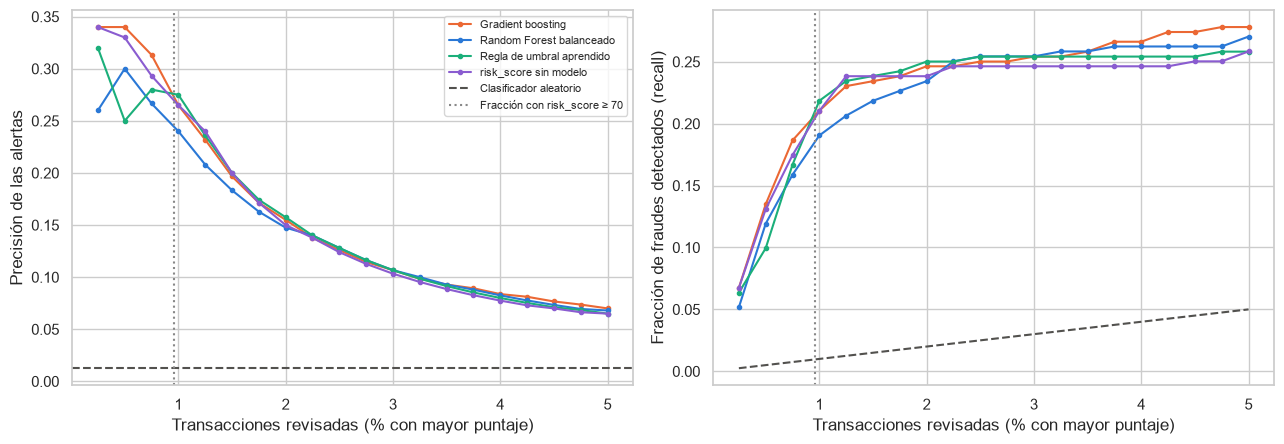

precisión                   recall                   mejora frente al azar                    
% revisado                    0.500 1.000 2.000 5.000  0.500 1.000 2.000 5.000                 0.500  1.000  2.000 5.000
modelo                                                                                                                  
Gradient boosting             0.340 0.265 0.155 0.070  0.135 0.210 0.246 0.278                26.984 21.032 12.302 5.556
Random Forest balanceado      0.300 0.240 0.148 0.068  0.119 0.190 0.234 0.270                23.810 19.048 11.706 5.397
Regla de umbral aprendido     0.250 0.275 0.158 0.065  0.099 0.218 0.250 0.258                19.841 21.825 12.500 5.159
risk_score sin modelo         0.330 0.265 0.150 0.065  0.131 0.210 0.238 0.258                26.190 21.032 11.905 5.159

In [7]:
FRACCIONES = np.round(np.arange(0.0025, 0.0501, 0.0025), 4)
filas = []
for nombre, ss in puntajes.items():
    for j, ((_, te), s) in enumerate(zip(PARTICIONES, ss)):
        for f in FRACCIONES:
            filas.append({"modelo": nombre, "partición": j, "fracción": f,
                          "precisión": precision_top(y[te], s, f), "recall": recall_top(y[te], s, f)})
curvas = pd.DataFrame(filas)
media_op = curvas.groupby(["modelo", "fracción"], sort=False)[["precisión", "recall"]].mean().reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for nombre in puntajes:
    g = media_op[media_op["modelo"] == nombre]
    axes[0].plot(100 * g["fracción"], g["precisión"], "o-", ms=3, color=COLORES[nombre], label=nombre)
    axes[1].plot(100 * g["fracción"], g["recall"], "o-", ms=3, color=COLORES[nombre], label=nombre)
axes[0].axhline(y.mean(), ls="--", color=COLOR_REF, label="Clasificador aleatorio")
axes[1].plot(100 * FRACCIONES, FRACCIONES, ls="--", color=COLOR_REF, label="Clasificador aleatorio")
for ax in axes:
    ax.axvline(100 * alto.mean(), ls=":", color="#888888", label=f"Fracción con risk_score ≥ {UMBRAL}")
    ax.set_xlabel("Transacciones revisadas (% con mayor puntaje)")
axes[0].set_ylabel("Precisión de las alertas")
axes[1].set_ylabel("Fracción de fraudes detectados (recall)")
axes[0].legend(fontsize=8)
savefig("fig_punto_operacion")
plt.show()

tabla_op = media_op[media_op["fracción"].round(4).isin([0.005, 0.01, 0.02, 0.05])].copy()
tabla_op["mejora frente al azar"] = tabla_op["precisión"] / y.mean()
tabla_op["% revisado"] = 100 * tabla_op["fracción"]
tabla_op.pivot(index="modelo", columns="% revisado", values=["precisión", "recall", "mejora frente al azar"]).loc[list(puntajes)]

*Figura (punto de operación). Precisión de las alertas (izquierda) y fracción de fraudes detectados (derecha) según el porcentaje de transacciones revisadas, ordenadas de mayor a menor puntaje (media de las 10 particiones de prueba). La línea punteada vertical marca la fracción de transacciones con `risk_score` ≥ 70; la discontinua, un clasificador aleatorio.*

## 4. Ahorro económico (Correa Bahnsen et al., 2016)

La PR-AUC no dice cuánto dinero se evita perder. La métrica de ahorro (*savings*) de Correa Bahnsen et al., definida en la sección 3, compara el costo con el modelo frente a la mejor estrategia sin modelo:

$$\mathrm{Costo}=\sum_{i=1}^{N}\left[y_i\,(1-c_i)\,\mathrm{Monto}_i+c_i\,C_a\right],\qquad \mathrm{Ahorro}=\frac{\mathrm{Costo}_{\text{sin modelo}}-\mathrm{Costo}_{\text{modelo}}}{\mathrm{Costo}_{\text{sin modelo}}}$$

donde $c_i = 1$ si la transacción genera una alerta y $C_a$ es el costo de revisar una alerta. El costo sin modelo es el menor entre aprobar todo (se pierde el monto de todos los fraudes) y revisar todo ($N\,C_a$). Como en Correa Bahnsen et al. (2016), se supone que revisar una alerta evita la pérdida del fraude.

- **Política:** se alerta el 1 % o el 2 % de las transacciones con mayor puntaje.
- **Costo de revisión:** el conjunto de datos no lo informa, así que se reporta un análisis de sensibilidad con $C_a$ entre 0,5 y 20 USD.
- **Montos:** se recuperan como $e^{\texttt{amount\_log}} - 1$.

*Cómo leer los extremos.* Si revisar una alerta es muy barato, revisar todas las transacciones cuesta menos que perder los fraudes; esa pasa a ser la referencia y alertar solo el 1 % sale peor (ahorro negativo). Si es muy caro, revisar alertas cuesta más que los fraudes que evita, porque el monto mediano de un fraude es bajo. El ahorro solo es positivo en un rango intermedio de costos.

Monto total de los fraudes: 6,789 USD · monto mediano de un fraude: 25.4 USD


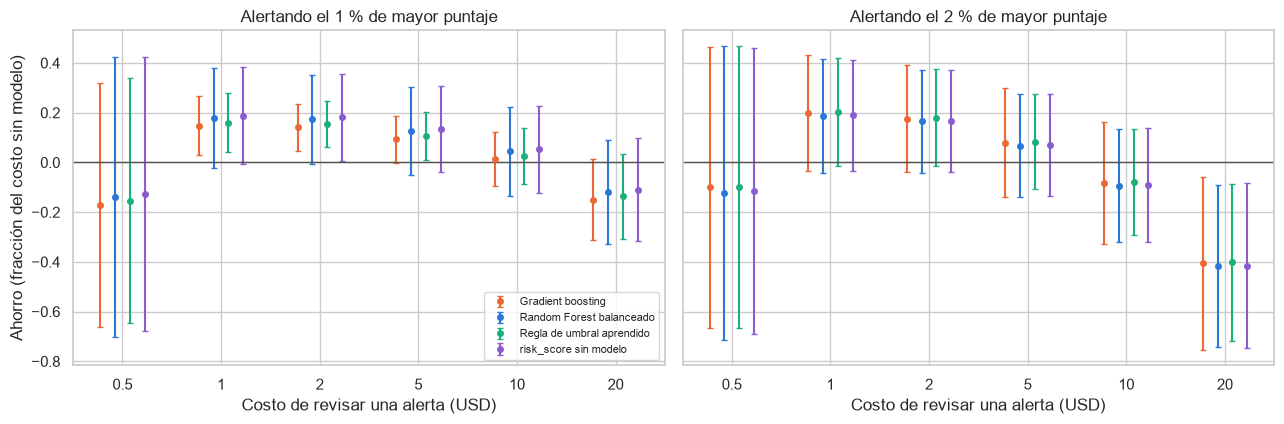

costo por alerta (USD),0.500,1.000,2.000,5.000,10.000,20.000
modelo,,,,,,
Gradient boosting,"-0.172 [-0.664, 0.321]","0.148 [0.028, 0.267]","0.141 [0.047, 0.236]","0.093 [-0.003, 0.188]","0.012 [-0.097, 0.121]","-0.150 [-0.312, 0.013]"
Random Forest balanceado,"-0.138 [-0.702, 0.426]","0.179 [-0.021, 0.380]","0.174 [-0.006, 0.353]","0.125 [-0.052, 0.302]","0.044 [-0.136, 0.224]","-0.117 [-0.327, 0.092]"
Regla de umbral aprendido,"-0.154 [-0.647, 0.340]","0.160 [0.040, 0.281]","0.154 [0.060, 0.248]","0.106 [0.009, 0.203]","0.025 [-0.089, 0.138]","-0.137 [-0.307, 0.033]"
risk_score sin modelo,"-0.127 [-0.677, 0.424]","0.188 [-0.006, 0.382]","0.182 [0.007, 0.356]","0.133 [-0.039, 0.306]","0.052 [-0.124, 0.228]","-0.109 [-0.315, 0.096]"


In [8]:
COSTOS_REVISION = [0.5, 1, 2, 5, 10, 20]


def ahorro(y_true, s, montos, fraccion, costo):
    k = int(np.ceil(fraccion * len(y_true)))
    alerta = np.zeros(len(y_true), dtype=bool)
    alerta[np.argsort(-np.asarray(s), kind="stable")[:k]] = True
    costo_modelo = montos[(y_true == 1) & ~alerta].sum() + costo * alerta.sum()
    costo_sin_modelo = min(montos[y_true == 1].sum(), costo * len(y_true))
    return (costo_sin_modelo - costo_modelo) / costo_sin_modelo


filas = []
for nombre, ss in puntajes.items():
    for f in [0.01, 0.02]:
        for c in COSTOS_REVISION:
            v = [ahorro(y[te], s, monto[te], f, c) for (_, te), s in zip(PARTICIONES, ss)]
            m, lo, hi = ic_nb(v)
            filas.append({"modelo": nombre, "% revisado": 100 * f, "costo por alerta (USD)": c,
                          "ahorro": m, "inf": lo, "sup": hi, "ahorro [IC 95 %]": f"{m:.3f} [{lo:.3f}, {hi:.3f}]"})
ahorros = pd.DataFrame(filas)
print(f"Monto total de los fraudes: {monto[y == 1].sum():,.0f} USD · monto mediano de un fraude: {np.median(monto[y == 1]):.1f} USD")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, f in zip(axes, [1.0, 2.0]):
    for j, nombre in enumerate(puntajes):
        g = ahorros[(ahorros["modelo"] == nombre) & (ahorros["% revisado"] == f)]
        x = np.arange(len(COSTOS_REVISION)) + (j - 1.5) * 0.15
        ax.errorbar(x, g["ahorro"], yerr=[g["ahorro"] - g["inf"], g["sup"] - g["ahorro"]], fmt="o", ms=4,
                    capsize=2, color=COLORES[nombre], label=nombre)
    ax.axhline(0, color=COLOR_REF, lw=1)
    ax.set_xticks(np.arange(len(COSTOS_REVISION)), [str(c) for c in COSTOS_REVISION])
    ax.set_xlabel("Costo de revisar una alerta (USD)")
    ax.set_title(f"Alertando el {f:.0f} % de mayor puntaje")
axes[0].set_ylabel("Ahorro (fracción del costo sin modelo)")
axes[0].legend(fontsize=8)
savefig("fig_ahorro")
plt.show()

ahorros[ahorros["% revisado"] == 1.0].pivot(index="modelo", columns="costo por alerta (USD)", values="ahorro [IC 95 %]").loc[list(puntajes)]

*Figura (ahorro). Ahorro económico (Correa Bahnsen et al., 2016) según el costo de revisar una alerta, alertando el 1 % (izquierda) o el 2 % (derecha) de las transacciones con mayor puntaje. Media e intervalo de confianza al 95 % con la corrección de Nadeau y Bengio sobre las 10 particiones de prueba. Un valor positivo significa que el modelo cuesta menos que la mejor estrategia sin modelo.*

## 5. ¿El modelo aprende algo real? Prueba de permutación

Que un intervalo de confianza no incluya el azar es una evidencia indirecta. La **prueba de permutación** (Ojala y Garriga, 2010) lo contrasta de forma directa: se baraja la etiqueta, se repite toda la validación cruzada y se registra la PR-AUC obtenida. Con 200 permutaciones se construye la distribución de la PR-AUC cuando no hay ninguna relación entre las variables y la etiqueta, y el p-valor es

$$p = \frac{1 + \#\{\text{permutaciones con PR-AUC} \geq \text{PR-AUC real}\}}{1 + 200}$$

(el mínimo posible es 1/201 ≈ 0,005). Se aplica al gradient boosting ponderado con validación cruzada estratificada de 5 particiones, en el conjunto D (con `risk_score`) y en el B (sin `risk_score`). Si la conclusión de las secciones 4 y 5 es correcta, el p-valor debe ser mínimo en D y alto en B.

D. Caracterizadas + risk: PR-AUC real 0.108 · con la etiqueta permutada: media 0.016, percentil 95 0.023 · p = 0.0050 (263 s acumulados)
B. Caracterizadas: PR-AUC real 0.015 · con la etiqueta permutada: media 0.016, percentil 95 0.023 · p = 0.4975 (476 s acumulados)


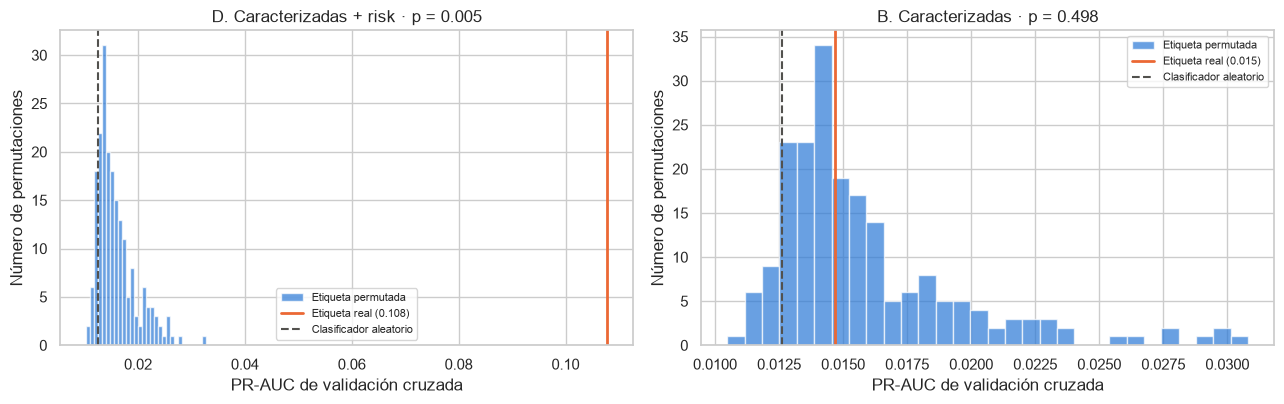

In [9]:
CV_PERM = StratifiedKFold(n_splits=N_PART, shuffle=True, random_state=RANDOM_STATE)
perm = {}
inicio = time.time()
for conjunto in ["D. Caracterizadas + risk", "B. Caracterizadas"]:
    obs, nulos, p = permutation_test_score(pipeline_gb(conjunto), df[columnas(conjunto)], y, scoring="average_precision",
                                           cv=CV_PERM, n_permutations=N_PERMUTACIONES, n_jobs=N_JOBS,
                                           random_state=RANDOM_STATE)
    perm[conjunto] = (obs, nulos, p)
    print(f"{conjunto}: PR-AUC real {obs:.3f} · con la etiqueta permutada: media {nulos.mean():.3f}, "
          f"percentil 95 {np.percentile(nulos, 95):.3f} · p = {p:.4f} ({time.time() - inicio:.0f} s acumulados)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (conjunto, (obs, nulos, p)) in zip(axes, perm.items()):
    ax.hist(nulos, bins=30, color="#2a78d6", alpha=0.7, label="Etiqueta permutada")
    ax.axvline(obs, color="#eb6834", lw=2, label=f"Etiqueta real ({obs:.3f})")
    ax.axvline(y.mean(), color=COLOR_REF, ls="--", label="Clasificador aleatorio")
    ax.set_title(f"{conjunto} · p = {p:.3f}")
    ax.set_xlabel("PR-AUC de validación cruzada")
    ax.set_ylabel("Número de permutaciones")
    ax.legend(fontsize=8)
savefig("fig_permutacion")
plt.show()

*Figura (prueba de permutación). Distribución de la PR-AUC de validación cruzada del gradient boosting ponderado cuando se baraja la etiqueta (200 permutaciones), frente a la PR-AUC con la etiqueta real (línea naranja), con `risk_score` (izquierda, conjunto D) y sin él (derecha, conjunto B).*

## 6. ¿Mejoraría con más datos? Curva de aprendizaje

Una pregunta natural es si el desempeño está limitado por el número de fraudes (101 en cada partición de entrenamiento) o por la información que contienen las variables. Para responderla se entrena el gradient boosting ponderado con el 10 %, 25 %, 50 %, 75 % y 100 % de cada partición de entrenamiento (de unas 800 a 8.000 transacciones, es decir, de unos 10 a 101 fraudes) y se evalúa siempre en la partición de prueba completa.

- Si la curva del conjunto D **sigue subiendo** al final, más datos ayudarían.
- Si **se aplana cerca del techo**, el límite está en las variables: más transacciones del mismo tipo no mejorarían el resultado.
- La curva del conjunto B (sin `risk_score`) debería quedarse en el nivel del azar para cualquier tamaño.

Los intervalos usan la corrección de Nadeau y Bengio con $n_{\text{prueba}}/n_{\text{entrenamiento}}$ propio de cada tamaño.

D. Caracterizadas + risk: listo (12 s acumulados)
B. Caracterizadas: listo (23 s acumulados)


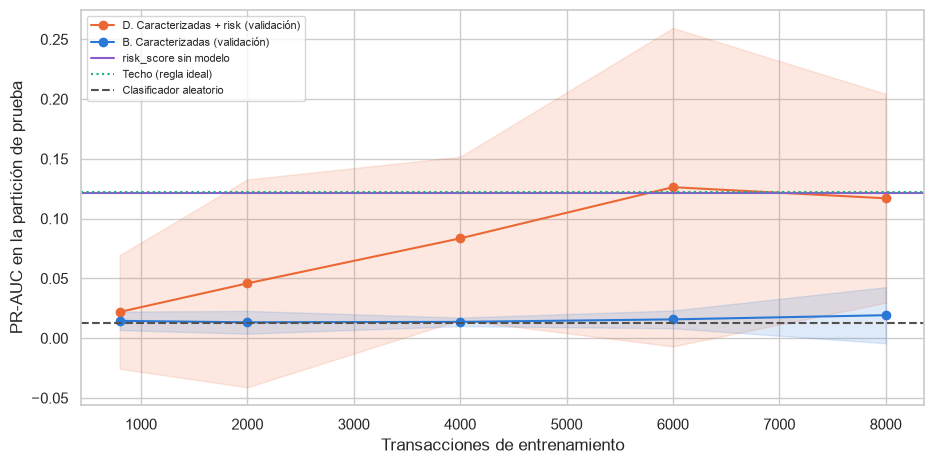

fraudes de entrenamiento (aprox.)  PR-AUC entrenamiento PR-AUC prueba [IC 95 %]
conjunto                 transacciones de entrenamiento                                                                                 
D. Caracterizadas + risk 800                                                            10                 0.913   0.022 [-0.026, 0.069]
                         2000                                                           25                 0.478   0.046 [-0.041, 0.133]
                         4000                                                           50                 0.290    0.083 [0.015, 0.152]
                         6000                                                           76                 0.240   0.126 [-0.007, 0.259]
                         8000                                                          101                 0.215    0.117 [0.030, 0.204]
B. Caracterizadas        800                                                            10                 0.913    0.015 [0.007, 0.022]
                         2000                                                           25                 0.465    0.013 [0.004, 0.023]
                         4000                                                           50                 0.221    0.014 [0.010, 0.017]
                         6000                                                           76                 0.147    0.016 [0.008, 0.023]
                         8000                                                          101                 0.111   0.019 [-0.004, 0.043]

In [10]:
TAMANOS = [0.1, 0.25, 0.5, 0.75, 1.0]
curvas_ap = {}
inicio = time.time()
for conjunto in ["D. Caracterizadas + risk", "B. Caracterizadas"]:
    n, puntaje_tr, puntaje_va = learning_curve(pipeline_gb(conjunto), df[columnas(conjunto)], y, train_sizes=TAMANOS,
                                               cv=PARTICIONES, scoring="average_precision", n_jobs=N_JOBS,
                                               shuffle=True, random_state=RANDOM_STATE)
    curvas_ap[conjunto] = (n, puntaje_tr, puntaje_va)
    print(f"{conjunto}: listo ({time.time() - inicio:.0f} s acumulados)")
ref_riesgo = [average_precision_score(y[te], riesgo[te]) for _, te in PARTICIONES]

fig, ax = plt.subplots(figsize=(9.5, 4.8))
filas = []
for conjunto, color in zip(curvas_ap, ["#eb6834", "#2a78d6"]):
    n, puntaje_tr, puntaje_va = curvas_ap[conjunto]
    est = np.array([ic_nb(puntaje_va[i], r=N_PRUEBA / n[i]) for i in range(len(n))])
    ax.plot(n, est[:, 0], "o-", color=color, label=f"{conjunto} (validación)")
    ax.fill_between(n, est[:, 1], est[:, 2], color=color, alpha=0.15)
    for i in range(len(n)):
        filas.append({"conjunto": conjunto, "transacciones de entrenamiento": n[i],
                      "fraudes de entrenamiento (aprox.)": round(n[i] * y.mean()),
                      "PR-AUC entrenamiento": puntaje_tr[i].mean(),
                      "PR-AUC prueba [IC 95 %]": fmt_nb(puntaje_va[i], r=N_PRUEBA / n[i])})
ax.axhline(np.mean(ref_riesgo), color=COLORES["risk_score sin modelo"], label="risk_score sin modelo")
ax.axhline(TECHO, color="#1baf7a", ls=":", label="Techo (regla ideal)")
ax.axhline(y.mean(), color=COLOR_REF, ls="--", label="Clasificador aleatorio")
ax.set_xlabel("Transacciones de entrenamiento")
ax.set_ylabel("PR-AUC en la partición de prueba")
ax.legend(fontsize=8)
savefig("fig_curva_aprendizaje")
plt.show()

pd.DataFrame(filas).set_index(["conjunto", "transacciones de entrenamiento"])

*Figura (curva de aprendizaje). PR-AUC del gradient boosting ponderado en la partición de prueba según el número de transacciones de entrenamiento, con y sin `risk_score` (media e intervalo de confianza al 95 % con la corrección de Nadeau y Bengio sobre las 10 particiones externas). Las líneas horizontales son `risk_score` sin modelo, el techo de la regla ideal y un clasificador aleatorio. Los límites inferiores negativos son un artefacto de la aproximación normal del intervalo; la PR-AUC no puede ser negativa.*

## 7. Comparación con el estado del arte

Los trabajos de la sección 3 usan conjuntos de datos con tasas de fraude muy distintas, y tanto la PR-AUC como la precisión de las alertas dependen de esa tasa: un clasificador aleatorio obtiene en ambas una cifra igual a la tasa de fraude. Por eso, además del valor absoluto, se compara la **mejora frente al azar** (la métrica dividida por la tasa de fraude). Es una comparación aproximada, porque las métricas, los datos y los protocolos de validación no son idénticos: sirve para ubicar el resultado, no para ordenarlo.

In [11]:
gb = res["Gradient boosting"]
comparacion = pd.DataFrame([
    {"trabajo": "Makki et al., 2019 [5]", "datos": "Reales (ccFraud), 10 millones", "tasa de fraude (%)": 5.96,
     "métrica": "PR-AUC", "valor": 0.66},
    {"trabajo": "Dal Pozzolo et al., 2018 [1]", "datos": "Reales, 21,8 y 54,8 millones", "tasa de fraude (%)": 0.2,
     "métrica": "Precisión en las 100 alertas diarias", "valor": 0.77},
    {"trabajo": "Este proyecto (gradient boosting)", "datos": "Sintéticos, 10.000", "tasa de fraude (%)": 100 * y.mean(),
     "métrica": "PR-AUC", "valor": gb["PR-AUC"].mean()},
    {"trabajo": "Este proyecto (gradient boosting)", "datos": "Sintéticos, 10.000", "tasa de fraude (%)": 100 * y.mean(),
     "métrica": "Precisión al revisar el 1 %", "valor": gb["Precisión@1 %"].mean()},
])
comparacion["mejora frente al azar (veces)"] = comparacion["valor"] / (comparacion["tasa de fraude (%)"] / 100)
comparacion.set_index("trabajo")

,datos,tasa de fraude (%),métrica,valor,mejora frente al azar (veces)
trabajo,,,,,
"Makki et al., 2019 [5]","Reales (ccFraud), 10 millones",5.960,PR-AUC,0.660,11.074
"Dal Pozzolo et al., 2018 [1]","Reales, 21,8 y 54,8 millones",0.200,Precisión en las 100 alertas diarias,0.770,385.000
Este proyecto (gradient boosting),"Sintéticos, 10.000",1.260,PR-AUC,0.117,9.325
Este proyecto (gradient boosting),"Sintéticos, 10.000",1.260,Precisión al revisar el 1 %,0.265,21.032


*Nota.* La tasa de fraude de Dal Pozzolo et al. (2018) es aproximada (≈ 0,2 %), así que su mejora frente al azar es un orden de magnitud y no una cifra exacta. Correa Bahnsen et al. (2016) reportan el ahorro económico relativo entre sus modelos; aquí se usó su métrica en el apartado 4, pero sus cifras no son comparables directamente porque dependen de los montos y costos de cada banco.

**Nota sobre las cifras del gradient boosting.** La PR-AUC del gradient boosting aparece con valores distintos según el protocolo de cada notebook:

| Dónde | Valor | Protocolo |
|---|---|---|
| Notebook 03, validación | 0,145 | Conjunto D; mejor configuración sobre el 80 % de entrenamiento (optimista por la selección de hiperparámetros) |
| Notebook 03, validación anidada | 0,119 | Conjunto D; 10 particiones externas; hiperparámetros elegidos en un bucle interno |
| Notebook 04, control de desbalance | 0,121 | Conjunto C (sin variables de historial); hiperparámetros fijos del notebook 03 |
| Notebook 04, validación aleatoria del apartado 6.1 | 0,120 | Conjunto D; hiperparámetros fijos |
| Este notebook, apartado 2 | 0,117 | Conjunto D; hiperparámetros fijos; 10 particiones externas |
| Este notebook, prueba de permutación | 0,108 | Conjunto D; 5 particiones, una sola repetición |

Las diferencias entre filas son menores que la amplitud de los intervalos de confianza y obedecen al conjunto de variables, a la elección de hiperparámetros y al número de particiones.

## 8. Discusión y conclusiones

Todas las cifras provienen de las 10 particiones externas compartidas con los notebooks 03 y 04, con intervalos al 95 % con la corrección de Nadeau y Bengio, salvo que se indique otra cosa.

**1. Por qué existe un techo.** La etiqueta se comporta como si proviniera de dos mecanismos. Por encima de `risk_score` = 70 hay 96 transacciones con 30 fraudes (31 %); por debajo, 9.904 transacciones con 96 fraudes (0,97 %). En el grupo bajo, que concentra el 76 % de los fraudes, la tasa de fraude es constante en todos los deciles de `risk_score` (p = 0,985) y ninguna de las 22 variables distingue los fraudes de las transacciones normales (q mínimo = 0,14). En el grupo alto tampoco (q mínimo = 0,93), ni siquiera el propio `risk_score` (AUC 0,52). Por tanto, **para tres de cada cuatro fraudes no se detecta ninguna señal en las variables disponibles**, y con 96 fraudes no se descartan efectos pequeños. Bajo ese supuesto, la mejor ordenación es marcar primero el grupo alto, que da una PR-AUC ≈ 0,12 (el techo del notebook 04). El límite parece ser de información del conjunto de datos, no de los algoritmos.

**2. Modelo final.** Los candidatos son estadísticamente equivalentes entre sí y con `risk_score` usado sin modelo:

| Candidato | PR-AUC | Precisión al revisar el 1 % | Recall al revisar el 1 % | Diferencia de PR-AUC con `risk_score` (p) |
|---|---|---|---|---|
| Gradient boosting ponderado | 0,117 [0,031; 0,204] | 0,265 | 0,210 | −0,004 (p = 0,88) |
| Random Forest balanceado | 0,099 [0,027; 0,172] | 0,240 | 0,190 | −0,022 (p = 0,43) |
| Regla de umbral aprendido | 0,087 [0,022; 0,152] | 0,275 | 0,218 | −0,034 (p = 0,086) |
| `risk_score` sin modelo | 0,121 [0,045; 0,197] | 0,265 | 0,210 | — |

El gradient boosting ponderado es el mejor modelo de aprendizaje de máquina (y el de mayor PR-AUC en la validación anidada del notebook 03, 0,119), pero no supera a `risk_score` usado solo. Siguiendo la recomendación del profesor de **no descartar variables**, el modelo final se entrena con todas las variables: con las particiones aleatorias de este notebook, el mejor es el gradient boosting ponderado con el conjunto D, y con el protocolo temporal del notebook 06, que incluye las nuevas probabilidades de historial, el modelo final es el Random Forest balanceado con todas las variables (punto 8). Como resultado complementario, la sección 5 y este apartado muestran que, si se quisiera simplificar, bastaría con `risk_score`: la regla de umbral aprendido (una sola variable y un umbral estable, con mediana 69,9 y rango 69,9–70,6) rinde de forma equivalente en las alertas (precisión 0,275 y recall 0,218 al revisar el 1 %, frente a 0,265 y 0,210 del gradient boosting y de `risk_score` sin modelo). Su PR-AUC es menor, posiblemente porque asigna solo dos puntajes (la PR-AUC penaliza los empates) y descarta el orden dentro de cada grupo.

**3. Utilidad práctica.** El presupuesto del 2 % usado en las secciones anteriores subestima el valor del modelo, porque solo cerca del 1 % de las transacciones tiene `risk_score` alto. Revisando el 1 % de mayor puntaje, cerca de **1 de cada 4 alertas es un fraude real** (precisión de 0,265 a 0,275 según el candidato), unas **21 veces más que revisar al azar**, y se detecta alrededor del 21 % de los fraudes. Revisando solo el 0,5 %, la precisión del gradient boosting sube a 0,34 (27 veces el azar), a cambio de detectar el 13,5 % de los fraudes; revisar más del 1 % casi no detecta fraudes adicionales (el 5 % detecta el 26–28 %). En términos económicos (métrica de ahorro de Correa Bahnsen et al., 2016), alertando el 1 % y con un costo de revisión de 1 a 2 USD por alerta, el ahorro es de alrededor del **14 % al 19 % del costo sin modelo** (en promedio; los intervalos de varios candidatos incluyen el 0; por ejemplo, regla de umbral: 0,160 [0,040; 0,281] con 1 USD y 0,154 [0,060; 0,248] con 2 USD). Con 5 USD baja a entre 0,09 y 0,13, y con 0,5 o 20 USD es negativo: si revisar es muy barato conviene revisarlo todo, y si es muy caro, revisar cuesta más que los fraudes que evita (el fraude mediano es de 25,4 USD).

**4. El aprendizaje es real.** La prueba de permutación confirma de forma directa lo que mostraban los intervalos. Con `risk_score`, la PR-AUC real (0,108 en esta validación de 5 particiones) está muy por encima de lo que se obtiene con la etiqueta barajada (media 0,016; percentil 95 0,023), con **p = 0,005, el mínimo posible con 200 permutaciones**. Sin `risk_score`, la PR-AUC real (0,015) es igual a la de la etiqueta barajada (0,016), con **p = 0,50**: sin esa variable, el modelo no aprende nada distinto del azar.

**5. Con más datos del mismo tipo no se espera superar el techo.** La curva de aprendizaje del conjunto D sube de 0,022 con unos 10 fraudes de entrenamiento a 0,083 con 50 y a 0,126 con 76; entre 76 y 101 fraudes no mejora (0,126 y 0,117, con intervalos amplios) y se ubica en el nivel de `risk_score` sin modelo. La del conjunto B se queda en el nivel del azar (de 0,013 a 0,019) para cualquier tamaño. Además, la PR-AUC de entrenamiento baja de 0,91 a 0,22 a medida que crece el conjunto, es decir, el sobreajuste disminuye pero la prueba no mejora. Con estos tamaños, lo que falta parece ser información y no cantidad de datos; con una cantidad mucho mayor de fraudes podrían detectarse señales débiles que aquí no son visibles.

**6. Comparación con el estado del arte.** En valor absoluto, la PR-AUC de este proyecto (0,117) es muy inferior a la de Makki et al. (2019; 0,66), pero su tasa de fraude es casi cinco veces mayor (5,96 % frente a 1,26 %). Relativo al azar, el resultado es del **mismo orden: 9,3 veces frente a 11,1 veces**, y la precisión al revisar el 1 % es 21 veces el azar. Dal Pozzolo et al. (2018) llegan mucho más lejos (precisión de 0,77 en las 100 alertas diarias, del orden de 385 veces el azar), porque trabajan con millones de transacciones reales y con variables que este conjunto de datos no tiene: historial de la tarjeta durante meses, comercio, ubicación y retroalimentación de los investigadores. Además, los mismos modelos rinden peor sobre datos simulados que sobre datos reales (Jemai et al., 2024). La conclusión de la sección 3 se confirma: con este conjunto de datos se esperaban resultados más bajos que los de la literatura, y la diferencia se explica por la información disponible y no por la metodología.

**7. Limitaciones y trabajo futuro.**
- El conjunto de datos es sintético y no documenta cómo se generaron `is_fraud` ni `risk_score`, así que no se puede saber si `risk_score` contiene información de la etiqueta; el desempeño debe interpretarse con esa cautela (sección 2.4).
- El umbral de 70 se identificó en el análisis exploratorio con todos los datos, por lo que el techo y el apartado 1 son descriptivos. La regla, en cambio, aprende su umbral solo con los datos de entrenamiento de cada partición.
- Los hiperparámetros de este notebook se heredan del notebook 03, lo que introduce un optimismo leve; la estimación sin ese sesgo es la validación anidada del notebook 03.
- Con 126 fraudes, la potencia estadística es baja: que una diferencia no sea significativa no prueba que los modelos sean idénticos.
- **Trabajo futuro:** incorporar variables del comercio, del dispositivo, de la ubicación y agregados de la tarjeta, o trabajar con datos reales.

**8. Protocolo temporal y recomendaciones de la asesoría (notebook 06).** Con el protocolo que pidió el profesor, las conclusiones se mantienen:
- **Particiones temporales.** En el *backtesting* mensual (febrero a agosto de 2026, 71 fraudes), ningún modelo supera al azar sin `risk_score` (el mejor, 0,019 [0,012; 0,049], frente a 0,012), y con `risk_score` el mejor es el Random Forest balanceado (0,132 [0,068; 0,238]), que no supera a `risk_score` sin modelo (0,159 [0,082; 0,270]). Con todas las variables, la partición aleatoria, la temporal 80/20 y el *backtesting* dan resultados equivalentes, con intervalos que se solapan.
- **Probabilidades de historial.** Ninguna de las 29 variables nuevas tiene señal (q > 0,86), ni con toda la historia ni con la ventana de 30 días, y agregarlas no mejora a ningún modelo. Isolation Forest y One-Class SVM sobre ellas quedan en el azar (PR-AUC de 0,014 a 0,018 en el *backtesting*).
- **Control positivo.** Una moneda nueva simulada se detecta perfectamente (AUC 1,000 con `p_currency` y de 0,980 a 1,000 con los detectores), y un monto 15 veces mayor, con AUC 0,893. El método detectaría los fraudes si fueran atípicos para su usuario; no lo son.
- **Modelo final.** Con todas las variables y la validación temporal con más fraudes, el modelo final es el Random Forest balanceado (0,116 [0,060; 0,208] en el *backtesting*, equivalente a `risk_score` sin modelo). La selección con solo 55 fraudes anteriores a febrero resultó inestable: eligió una SVM que rinde 0,025, porque una de sus particiones de validación no tenía fraudes detectables.

**Conclusión general.** Aunque el desempeño absoluto es bajo, los resultados son consistentes en todas las validaciones empleadas (cruzada, anidada, temporal, agrupada por usuario y el protocolo temporal completo del notebook 06). No se observa que los modelos extraigan más información que la contenida en `risk_score`: alcanzan el techo, el aprendizaje es real (p = 0,005) y el resultado se mantiene con validación temporal, agrupada por usuario y anidada. El límite está en el conjunto de datos: para tres de cada cuatro fraudes no se detecta ninguna variable que los delate. Dentro de ese límite, el modelo final convierte una tasa de fraude del 1,26 % en alertas donde cerca de 1 de cada 4 es fraude, con un ahorro estimado de entre el 14 % y el 19 % del costo del fraude para costos de revisión moderados.